In [22]:
import numpy as np
import matplotlib.pyplot as plt

def convolucao_linear(x1_n, x2_n, N):

    # Zero-padding dos sinais x1_n e x2_n para ter N amostras:
    x1_n_pad = np.pad(x1_n, (0, N - len(x1_n)), 'constant')
    x2_n_pad = np.pad(x2_n, (0, N - len(x2_n)), 'constant')

    # Cálculo da DFT dos sinais x1_n e x2_n
    X1_k = DFT(x1_n_pad, N)
    X2_k = DFT(x2_n_pad, N)

    # Multiplicação ponto a ponto das DFTs
    Y_k = X1_k * X2_k

    # Cálculo da IDFT do resultado
    y_n = IDFT(Y_k, N)

    return y_n

def W_kn_N (k,n,N):
    return np.exp(-2j * np.pi * k * n / N)

def DFT(x_n, N):

    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da DFT
    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        X_k[k] = np.sum(W_n[k] * x_n )

    return X_k

def IDFT(X_k, N):
    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da IDFT
    x_n = np.zeros(N, dtype=complex)
    for n in range(N):
        x_n[n] = np.sum( np.conj(W_n[:,n]) * X_k ) / N

    return x_n

def convolucao_circular(x1_n, x2_n, N):
    y_n = np.zeros(N, dtype=complex)
    for n in range(N):
        for m in range(N):
            y_n[n] += x1_n[m] * x2_n[(n - m) % N]
    return y_n

In [23]:
def overlap_add(x1_n, x2_n, N):
    K = len(x2_n)
    N_dft = N + K - 1
    
    # 1. Divisão de x1_n em blocos de tamanho N
    num_blocos = int(np.ceil(len(x1_n) / N))
    x1_n_pad = np.pad(x1_n, (0, num_blocos * N - len(x1_n)), 'constant')
    blocos = np.reshape(x1_n_pad, (num_blocos, N)) # Matriz de blocos (num_blocos, N)

    # 2. Preenchimento de zeros em x1_n_pad e x2_n para o tamanho N_dft
    x1_n_pad = np.zeros((num_blocos, N_dft), dtype=complex)
    for i in range(num_blocos):
        bloco = blocos[i]
        x1_n_pad[i] = np.pad(bloco, (0, K - 1), 'constant')

    x2_n_pad = np.pad(x2_n, (0, N_dft - K), 'constant')

    # 3. Cálculo da DFT de cada bloco x_m
    X_m_k = np.zeros((num_blocos, N_dft), dtype=complex)
    for i in range(num_blocos):
        X_m_k[i] = DFT(x1_n_pad[i], N_dft)
    
    # 4. Cálculo da DFT de x2_n
    X2_k = DFT(x2_n_pad, N_dft)

    # 5. Multiplicação ponto a ponto das DFTs
    Y_m_k = np.zeros((num_blocos, N_dft), dtype=complex)
    for i in range(num_blocos):
        Y_m_k[i] = X_m_k[i] * X2_k

    # 6. Cálculo da IDFT de cada Y_m_k
    y_m_n = np.zeros((num_blocos, N_dft), dtype=complex)
    for i in range(num_blocos):
        y_m_n[i] = IDFT(Y_m_k[i], N_dft)
    
    # 7. Sobreposição e adição dos blocos y_m_n
    tamanho_processado = num_blocos * N + K - 1
    y_n = np.zeros(tamanho_processado, dtype=complex)
    for i in range(num_blocos):
        y_n[i*N:i*N + N_dft] += y_m_n[i]

    # Retorna o resultado cortado no tamanho real da convolução linear
    return y_n[:len(x1_n) + len(x2_n) - 1]

def overlap_save(x1_n, x2_n, N):
    K = len(x2_n)
    
    if K > N:
        raise ValueError("O tamanho do filtro x2_n deve ser menor ou igual a N.")
    
    N_dft = N # Tamanho do DFT que será calculado
    d = N - K + 1  # Número de amostras úteis (salvas) por bloco
    
    # Tamanho real da convolução linear
    tamanho_real = len(x1_n) + len(x2_n) - 1
    
    # 1. Determina o número de blocos necessários para cobrir toda a saída
    num_blocos = int(np.ceil(tamanho_real / d))
    
    # 2. Preenchimento (padding) de x1_n:
    #    - (K - 1) zeros no INÍCIO de x1_n
    #    - Zeros no FINAL para preencher até o último bloco completo
    total_amostras_necessarias = num_blocos * d
    pad_final = total_amostras_necessarias - len(x1_n)
    x1_pad = np.pad(x1_n, (K - 1, pad_final), 'constant')
    
    # 3. Monta a matriz de blocos de entrada de tamanho N com deslocamento d
    blocos = np.zeros((num_blocos, N_dft), dtype=complex)
    for i in range(num_blocos):
        start = i * d
        blocos[i] = x1_pad[start : start + N_dft]
        
    # 4. Cálculo da DFT de x2_n com zero-padding até N_dft
    x2_n_pad = np.pad(x2_n, (0, N_dft - K), 'constant')
    X2_k = DFT(x2_n_pad, N_dft)

    # 5 e 6. DFT do bloco, multiplicação ponto a ponto e IDFT
    y_m_n = np.zeros((num_blocos, N_dft), dtype=complex)
    for i in range(num_blocos):
        X_m_k = DFT(blocos[i], N_dft)
        Y_m_k = X_m_k * X2_k
        y_m_n[i] = IDFT(Y_m_k, N_dft)
    
    # 7. Descarte dos K-1 primeiros termos de cada bloco (que contêm o aliasing circular)
    y_m = y_m_n[:, K - 1:]  # Matriz de formato (num_blocos, d)
    
    # 8. Concatenaros blocos num único vetor 1D
    y_n = y_m.reshape(-1)
    
    # 9. Retorna cortado no tamanho exato da convolução linear
    return y_n[:tamanho_real]


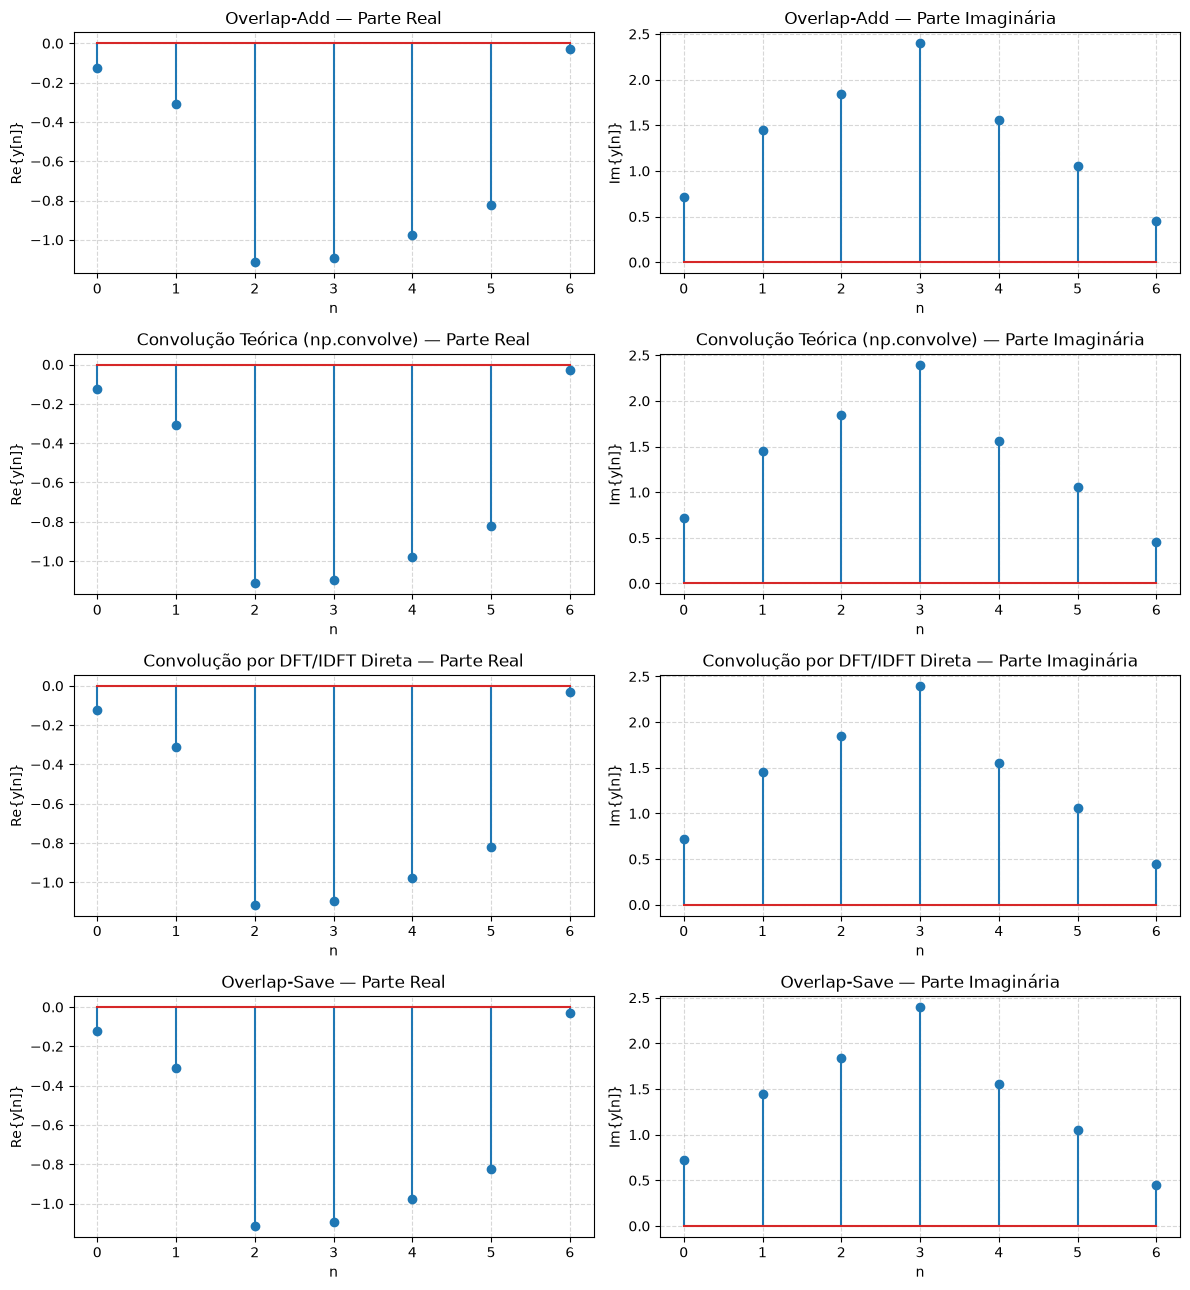

Os resultados são iguais? True


In [24]:
# Sinais aleatórios para teste

L1 = 4 # Tamanho do sinal x1_n
L2 = 4 # Tamanho do sinal x2_n
x1_n = np.random.rand(L1) + 1j * np.random.rand(L1)
x2_n = np.random.rand(L2) + 1j * np.random.rand(L2)

N = 4 # Tamanho da DFT que será usado nos blocos (arbitrário em ola, mas condiccional em ols: N >= L2))
y_n_ola = overlap_add(x1_n, x2_n, N)
y_n_ols = overlap_save(x1_n, x2_n, N)

# Cálculo da convolução linear usando a função np.convolve
y_n_linear_teo = np.convolve(x1_n, x2_n)

# Cálculo da convolução linear usando a função convolucao_linear
y_n_conv_linear = convolucao_linear(x1_n, x2_n, len(x1_n) + len(x2_n) - 1) # Respeitando a ccondição de N_min = L1 + L2 - 1

# Grid 4x2: 4 métodos (linhas) x 2 componentes (colunas)
plt.figure(figsize=(12, 13))

# ----------------- LINHA 1: OVERLAP-ADD ----------------- #
plt.subplot(4, 2, 1)
plt.stem(y_n_ola.real)
plt.title('Overlap-Add — Parte Real')
plt.xlabel('n')
plt.ylabel('Re{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(4, 2, 2)
plt.stem(y_n_ola.imag)
plt.title('Overlap-Add — Parte Imaginária')
plt.xlabel('n')
plt.ylabel('Im{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

# ----------------- LINHA 2: TEÓRICA (np.convolve) ----------------- #
plt.subplot(4, 2, 3)
plt.stem(y_n_linear_teo.real)
plt.title('Convolução Teórica (np.convolve) — Parte Real')
plt.xlabel('n')
plt.ylabel('Re{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(4, 2, 4)
plt.stem(y_n_linear_teo.imag)
plt.title('Convolução Teórica (np.convolve) — Parte Imaginária')
plt.xlabel('n')
plt.ylabel('Im{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

# ----------------- LINHA 3: CALCULADA (convolucao_linear) ----------------- #
plt.subplot(4, 2, 5)
plt.stem(np.real(y_n_conv_linear))
plt.title('Convolução por DFT/IDFT Direta — Parte Real')
plt.xlabel('n')
plt.ylabel('Re{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(4, 2, 6)
plt.stem(np.imag(y_n_conv_linear))
plt.title('Convolução por DFT/IDFT Direta — Parte Imaginária')
plt.xlabel('n')
plt.ylabel('Im{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

# ----------------- LINHA 4: OVERLAP-SAVE ----------------- #
plt.subplot(4, 2, 7)
plt.stem(y_n_ols.real)
plt.title('Overlap-Save — Parte Real')
plt.xlabel('n')
plt.ylabel('Re{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(4, 2, 8)
plt.stem(y_n_ols.imag)
plt.title('Overlap-Save — Parte Imaginária')
plt.xlabel('n')
plt.ylabel('Im{y[n]}')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Compara a resposta completa (real + imaginário) da sua OLA com a convolução linear
print("Os resultados são iguais?", np.allclose(y_n_ola,y_n_ols))